# Sales Data Analysis Using Python

## Project Objective
The objective of this project is to analyze retail sales
data and identify useful business insights.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Key Questions
1. What is the total sales revenue?
2. Which products generate the highest sales?
3. Which categories perform best?
4. How do sales change over time?
5. Which regions perform best?

## Import libraries

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the dataset

In [10]:
df = pd.read_csv("superstore.csv", encoding="latin1")

## Display the first five rows

In [11]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## Check the dataset size

In [12]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9994
Number of columns: 21


## Inspect column names and data types

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

## Data Cleaning
### Check column names

In [14]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


## Check missing values

In [15]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


## Check duplicate rows

In [36]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


### Convert date columns

In [21]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


### Review numerical data

In [22]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


## Exploratory Data Analysis (EDA)

### Calculate total sales and profit

In [23]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02


### Sales by category

In [24]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


### Visualize sales by category

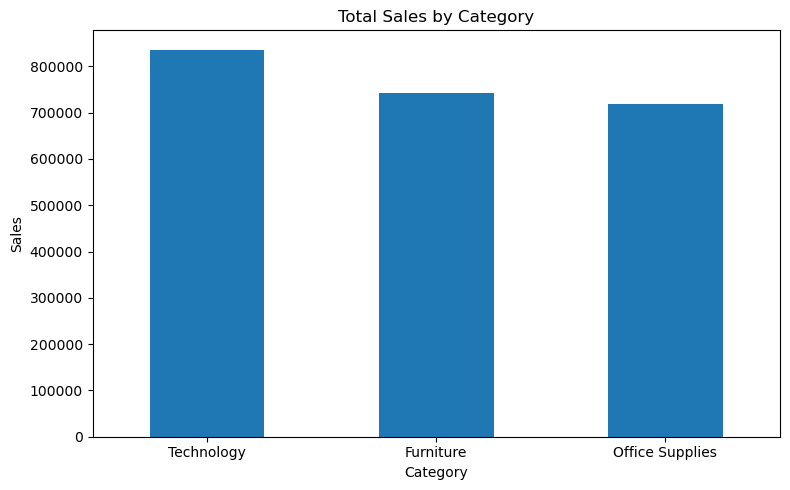

In [25]:
category_sales.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Category",
    xlabel="Category",
    ylabel="Sales"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Analyze sales by product

### Find the top 10 products by sales

In [26]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


### Visualize the top 10 products

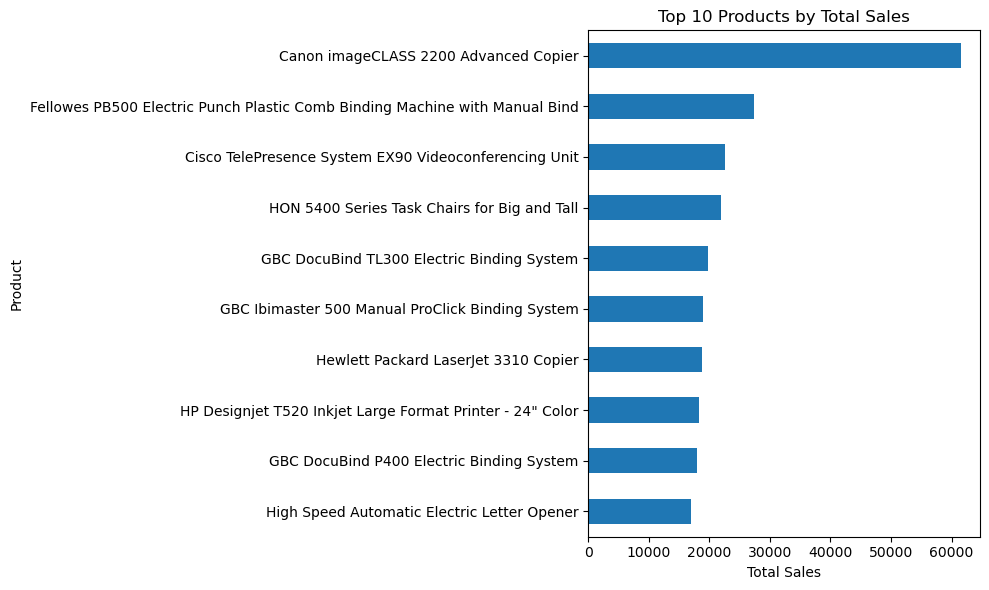

In [27]:
top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Products by Total Sales",
    xlabel="Total Sales",
    ylabel="Product"
)

plt.tight_layout()
plt.show()

## Analyze monthly sales trends

### Extract the month and year

In [29]:
df["Order Year-Month"] = (
    df["Order Date"].dt.to_period("M").astype(str)
)

monthly_sales = (
    df.groupby("Order Year-Month")["Sales"]
    .sum()
    .sort_index()
)

print(monthly_sales.head(10))

Order Year-Month
2014-01    14236.8950
2014-02     4519.8920
2014-03    55691.0090
2014-04    28295.3450
2014-05    23648.2870
2014-06    34595.1276
2014-07    33946.3930
2014-08    27909.4685
2014-09    81777.3508
2014-10    31453.3930
Name: Sales, dtype: float64


### Plot monthly sales

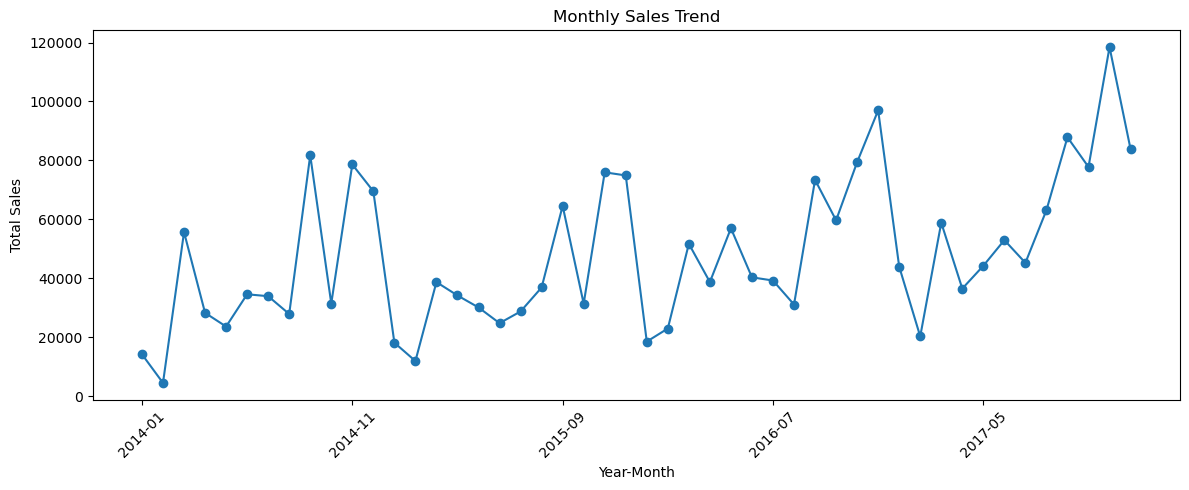

In [30]:
monthly_sales.plot(
    kind="line",
    figsize=(12, 5),
    marker="o",
    title="Monthly Sales Trend",
    xlabel="Year-Month",
    ylabel="Total Sales"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Analyze sales by region

### Calculate regional sales

In [31]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(region_sales)

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


### Create a regional sales chart

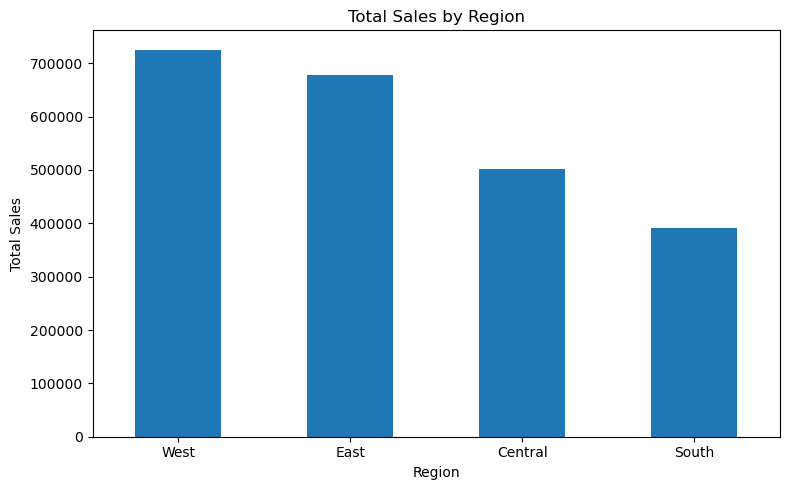

In [33]:
region_sales.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Region",
    xlabel="Region",
    ylabel="Total Sales"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Calculate profit margin

### Profit by category

In [34]:
category_performance = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
)

category_performance["Profit Margin (%)"] = (
    category_performance["Profit"]
    / category_performance["Sales"]
    * 100
)

print(category_performance.round(2))

                     Sales     Profit  Profit Margin (%)
Category                                                
Furniture        741999.80   18451.27               2.49
Office Supplies  719047.03  122490.80              17.04
Technology       836154.03  145454.95              17.40


## Business Insights and Key Findings

In this section, we identify the best-performing category, region, product, and month based on sales and profit data. These insights can help a business understand its performance and make better decisions.


### Calculate key business findings

In [35]:

# 1. Best-performing category by sales
category_sales = df.groupby("Category")["Sales"].sum()
best_category = category_sales.idxmax()

# 2. Best-performing region by sales
region_sales = df.groupby("Region")["Sales"].sum()
best_region = region_sales.idxmax()

# 3. Best-selling product by total sales
product_sales = df.groupby("Product Name")["Sales"].sum()
best_product = product_sales.idxmax()

# 4. Most profitable category
category_profit = df.groupby("Category")["Profit"].sum()
best_profit_category = category_profit.idxmax()

# 5. Least profitable category
worst_profit_category = category_profit.idxmin()

# 6. Overall business performance
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

profit_margin = (
    total_profit / total_sales * 100 if total_sales != 0 else 0
)

# Display findings
print("========== BUSINESS INSIGHTS ==========")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")
print(f"Top Category by Sales: {best_category}")
print(f"Top Region by Sales: {best_region}")
print(f"Top Product by Sales: {best_product}")
print(f"Most Profitable Category: {best_profit_category}")
print(f"Least Profitable Category: {worst_profit_category}")


========== BUSINESS INSIGHTS ==========
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Overall Profit Margin: 12.47%
Top Category by Sales: Technology
Top Region by Sales: West
Top Product by Sales: Canon imageCLASS 2200 Advanced Copier
Most Profitable Category: Technology
Least Profitable Category: Furniture



## Business Recommendations

Based on the analysis, the business should:

1. Improve sales performance: Study the highest-performing product categories and identify strategies to increase sales in weaker categories.
2. Optimize regional performance: Compare sales and profit across regions to identify opportunities for improvement.
3. Review profitability: Investigate categories with low or negative profit and examine discounts, costs, and pricing.
4. Monitor sales trends: Use monthly sales trends to support inventory planning and sales forecasting.
5. Focus on product performance: Identify products that generate strong sales and evaluate whether they also generate healthy profits.

Note: Final recommendations should be adjusted based on the actual results of the analysis.
